## Phase 1 — Data Collection & Preparation

In [5]:
import pandas as pd
import yfinance as yf
import os
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import adfuller
import warnings
warnings.filterwarnings("ignore")
from functools import reduce
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from statsmodels.tsa.ar_model import AutoReg

In [6]:
with open("repo_rate.csv", "w") as f:
    f.write("""date,repo
2012-01-01,8.50
2012-04-17,8.00
2013-05-03,7.50
2013-07-15,7.25
2013-09-20,7.50
2013-10-29,7.75
2013-12-18,8.00
2014-01-28,8.00
2014-06-03,8.00
2015-01-15,7.75
2015-03-04,7.50
2015-06-02,7.25
2015-09-29,6.75
2016-04-05,6.50
2017-08-02,6.00
2018-06-06,6.25
2018-08-01,6.50
2019-02-07,6.25
2019-04-04,6.00
2019-06-06,5.75
2019-08-07,5.40
2019-10-04,5.15
2020-03-27,4.40
2020-05-22,4.00
2022-05-04,4.40
2022-06-08,4.90
2022-08-05,5.40
2022-09-30,5.90
2022-12-07,6.25
2023-02-08,6.50
2024-10-09,6.25
2025-02-07,6.00
2025-04-09,5.75
2025-06-06,5.50""")

In [7]:
gdp_url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=INDGDPRQPSMEI"
gdp_df = pd.read_csv(gdp_url, parse_dates = ["observation_date"])
gdp_df = gdp_df[gdp_df["observation_date"] >= "2012-01-01"].reset_index(drop = True)
gdp_df.columns = ["date", "gdp_yoy"]
iip_url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=INDPROINDMISMEI"
iip_df = pd.read_csv(iip_url, parse_dates=["observation_date"])
iip_df = iip_df[iip_df["observation_date"] >= "2012-01-01"].reset_index(drop=True)
iip_df.columns = ["date", "iip"]
pmi_df = pd.read_csv("INDPRMNTO01GYSAM.csv", parse_dates = ["observation_date"])
pmi_df = pmi_df[pmi_df["observation_date"] >= "2012-01-01"].reset_index(drop = True)
pmi_df.columns = ["date", "pmi"]
nifty = yf.download("^NSEI", start="2012-01-01", interval="1mo")
cpi_df = pd.read_csv("INDCPIALLMINMEI.csv", parse_dates = ["observation_date"])
cpi_df.columns = ["date", "cpi"]
cpi_df = cpi_df[cpi_df["date"] >= "2012-01-01"].reset_index(drop = True)
repo_df = pd.read_csv("repo_rate.csv", parse_dates = ["date"])

[*********************100%***********************]  1 of 1 completed


In [8]:
nifty  = nifty['Close']

In [9]:
repo_df.set_index("date").resample("MS").ffill()
repo_df = repo_df.set_index("date").resample("MS").ffill().reset_index()
nifty = nifty["^NSEI"].reset_index()
nifty.columns = ["date", "nifty"]

Features: `gdp_df`, `iip_df`, `pmi_df`, `nifty`, `cpi_df`, `repo_df` \
Features needing log change due to non-stationarity are `iip_df`, `nifty`, `cpi_df`

In [10]:
iip_df['iip'] = np.log(iip_df['iip']).diff()
nifty['nifty'] = np.log(nifty['nifty']).diff()
cpi_df['cpi'] = np.log(cpi_df['cpi']).diff()

In [11]:
iip_df.head()

,date,iip
0,2012-01-01,NaN
1,2012-02-01,0.001180
2,2012-03-01,-0.008577
3,2012-04-01,-0.018176
4,2012-05-01,0.023387


In [12]:
iip_df = iip_df.dropna().reset_index(drop = True)
nifty = nifty.dropna().reset_index(drop = True)
cpi_df = cpi_df.dropna().reset_index(drop = True)

In [13]:
series_dict = {
    "iip": iip_df["iip"],
    "pmi": pmi_df["pmi"],
    "nifty": nifty["nifty"],
    "cpi": cpi_df["cpi"],
    "repo": repo_df["repo"]
}
for dataset, col in series_dict.items():
       p_value = adfuller(col)[1] 
       print(f"{dataset}: p-value = {p_value:.4f}")
       
#Rule: if p-value < 0.05, the series is stationary. If not, we have a problem.


iip: p-value = 0.0000
pmi: p-value = 0.0000
nifty: p-value = 0.0000
cpi: p-value = 0.1575
repo: p-value = 0.3382


In [14]:
cpi_df["cpi"][cpi_df['date'] >  "2012-01-01"].describe()

count    158.000000
mean       0.004636
std        0.006912
min       -0.016598
25%        0.000000
50%        0.004493
75%        0.008727
max        0.033788
Name: cpi, dtype: float64

<Axes: >

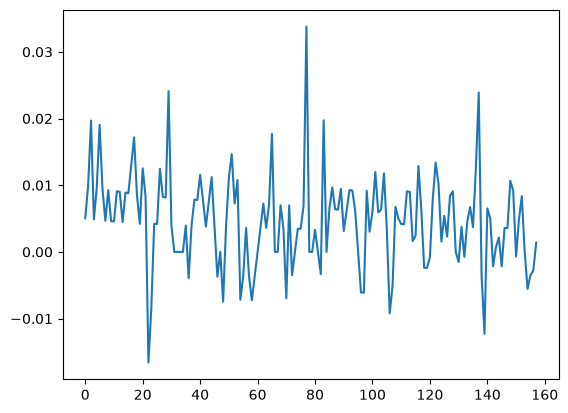

In [15]:
cpi_df['cpi'].plot()
#That looks stationary — it fluctuates around a stable mean near 0.005, no clear upward or downward trend.

<Axes: >

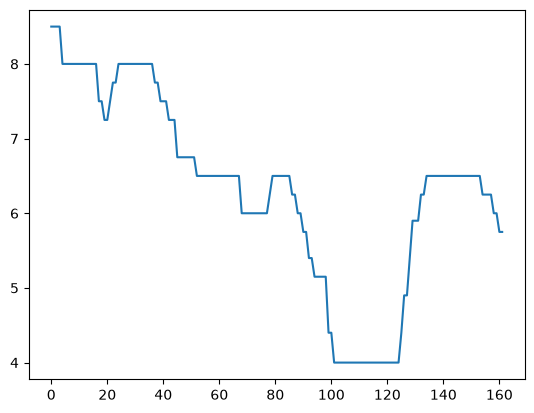

In [16]:
repo_df['repo'].plot()

### Data Sources
| Series | Frequency | Source | Transformation |
|--------|-----------|--------|----------------|
| GDP Growth | Quarterly | FRED (INDGDPRQPSMEI) | Already in YoY % — no change |
| IIP | Monthly | FRED (INDPROINDMISMEI) | Log-change |
| Manufacturing PMI | Monthly | FRED (INDPRMNTO01GYSAM) | None — already stationary |
| Nifty 50 | Monthly | Yahoo Finance (^NSEI) | Log-change |
| CPI | Monthly | FRED (INDCPIALLMINMEI) | Log-change |
| Repo Rate | Monthly | Manual CSV (RBI decisions) | None — kept in levels |

### Transformations
- **Log-change** applied to IIP, Nifty, and CPI to remove upward trends and achieve stationarity.
- **PMI** entered as levels — it is a bounded diffusion index with no trend.
- **Repo rate** forward-filled from RBI decision dates to monthly frequency using `resample("MS").ffill()`.

### Stationarity — ADF Test Results
| Series | p-value | Decision |
|--------|---------|----------|
| IIP | 0.0000 | Stationary ✓ |
| PMI | 0.0000 | Stationary ✓ |
| Nifty | 0.0000 | Stationary ✓ |
| CPI | 0.1575 | Borderline — visual inspection confirms no trend; kept as-is |
| Repo Rate | 0.3382 | Non-stationary — kept in levels per macro VAR convention |

### Notes
- IIP series on FRED cuts off at January 2023; noted as a data limitation.
- CPI borderline ADF result likely reflects low test power on a short sample (~130 observations).
- Repo rate non-stationarity is standard in macro VARs — the level carries economic meaning.

## Phase 2 — Mixed-Frequency Stacking


In [17]:
indicators = {
    "iip": iip_df,
    "pmi": pmi_df,
    "nifty": nifty,
    "cpi": cpi_df,
    "repo": repo_df
}
stacked = {}
for col, dataset in indicators.items():
    dataset['quarter'] = dataset['date'].dt.to_period('Q-MAR')
    months = dataset['date'].dt.month
    dataset['months_in_quarter'] = months % 3
    dataset['months_in_quarter'] = dataset['months_in_quarter'].replace(0,3)
    dataset = dataset.pivot(index="quarter", columns="months_in_quarter", values= col)
    dataset.columns = [f"{col}_m1", f"{col}_m2", f"{col}_m3"]
    stacked[col] = dataset.reset_index()

In [18]:
gdp_df['quarter'] = gdp_df['date'].dt.to_period('Q-MAR')

In [19]:
alldf = [stacked["iip"], stacked["pmi"], stacked["nifty"],stacked["cpi"], stacked["repo"], gdp_df[["quarter", "gdp_yoy"]]]
merged_df = reduce(lambda left, right: pd.merge(left, right, on="quarter", how="inner"), alldf)

In [20]:
merged_df.head()

,quarter,iip_m1,iip_m2,iip_m3,pmi_m1,pmi_m2,pmi_m3,nifty_m1,nifty_m2,nifty_m3,cpi_m1,cpi_m2,cpi_m3,repo_m1,repo_m2,repo_m3,gdp_yoy
0,2012Q4,NaN,0.001180,-0.008577,1.131522,0.535211,-3.392836,NaN,0.035140,-0.016788,NaN,0.005038,0.010000,8.5,8.5,8.5,4.027471
1,2013Q1,-0.018176,0.023387,-0.013000,-4.365741,1.673566,-4.118898,-0.008991,-0.063704,0.069546,0.019705,0.004866,0.009662,8.5,8.0,8.0,3.720960
2,2013Q2,-0.006424,0.002725,-0.015159,-1.328671,0.803748,-2.002556,-0.009498,0.005626,0.081199,0.019048,0.009390,0.004662,8.0,8.0,8.0,6.592034
3,2013Q3,0.025287,-0.011050,0.002666,7.381381,-4.716657,-3.474056,-0.014767,0.045253,0.004285,0.009259,0.004598,0.004577,8.0,8.0,8.0,5.869208
4,2013Q4,-0.000070,-0.002356,0.019032,-2.547276,-2.129570,0.221195,0.021718,-0.058288,-0.001846,0.009091,0.009009,0.004474,8.0,8.0,8.0,5.654434


### Why Stacking?
A VAR requires a single consistent time step. GDP is quarterly but our 
indicators are monthly. We can't merge them directly — the frequencies 
don't align. The stacking trick solves this by reshaping each monthly 
indicator into 3 quarterly variables representing month 1, month 2, and 
month 3 of each quarter.

### Approach
1. **Quarter labels** — assigned using `dt.to_period('Q-MAR')` to respect 
   India's fiscal year (April–March)
2. **Month-within-quarter** — computed as `month % 3`, with 0 replaced by 3
3. **Pivot** — reshaped each indicator from long (monthly rows) to wide 
   (one row per quarter, three columns per indicator)
4. **Merge** — joined all 5 stacked indicators with GDP on the `quarter` 
   column using `reduce` + `pd.merge`

### Result
A clean 43×17 matrix:
- 43 quarters (2013Q1 to 2023Q3)
- 16 model variables: 5 indicators × 3 months each
- 1 target variable: `gdp_yoy`

### Notes
- 2 incomplete quarters dropped (boundary NaNs from log-differencing)
- Filling with mean was rejected — boundary missingness is not random, 
  inventing edge values would bias the model
- 43 quarterly observations is standard for macro VAR estimation

In [21]:
var_data = merged_df.drop(columns = ["quarter"])

In [22]:
var_data.head()

,iip_m1,iip_m2,iip_m3,pmi_m1,pmi_m2,pmi_m3,nifty_m1,nifty_m2,nifty_m3,cpi_m1,cpi_m2,cpi_m3,repo_m1,repo_m2,repo_m3,gdp_yoy
0,NaN,0.001180,-0.008577,1.131522,0.535211,-3.392836,NaN,0.035140,-0.016788,NaN,0.005038,0.010000,8.5,8.5,8.5,4.027471
1,-0.018176,0.023387,-0.013000,-4.365741,1.673566,-4.118898,-0.008991,-0.063704,0.069546,0.019705,0.004866,0.009662,8.5,8.0,8.0,3.720960
2,-0.006424,0.002725,-0.015159,-1.328671,0.803748,-2.002556,-0.009498,0.005626,0.081199,0.019048,0.009390,0.004662,8.0,8.0,8.0,6.592034
3,0.025287,-0.011050,0.002666,7.381381,-4.716657,-3.474056,-0.014767,0.045253,0.004285,0.009259,0.004598,0.004577,8.0,8.0,8.0,5.869208
4,-0.000070,-0.002356,0.019032,-2.547276,-2.129570,0.221195,0.021718,-0.058288,-0.001846,0.009091,0.009009,0.004474,8.0,8.0,8.0,5.654434


## Phase 3 — Baseline VAR

### Why Standard VAR Failed

A standard VAR(1) with 16 variables requires estimating a 16×16 coefficient 
matrix — 256 parameters in total. With only 34 training observations, the 
system is severely underdetermined (far more parameters than data points), 
causing the SVD decomposition to fail during OLS estimation.

This is the core challenge of high-dimensional macro VARs and is precisely 
why Bayesian shrinkage (Phase 4) is needed. The Minnesota prior regularises 
the coefficient estimates, making the model estimable even when observations 
are scarce relative to parameters.

For Phase 3, we fit a reduced VAR on 3 variables (gdp_yoy, iip_m3, nifty_m3) 
as a baseline benchmark. This gives us a concrete RMSE to beat in Phase 4.

In [23]:
reduced = var_data[["gdp_yoy", "iip_m3", "nifty_m3"]]

In [24]:
train = reduced.iloc[:34]
test = reduced.iloc[34:]

In [25]:
print(train.shape)
test.shape

(34, 3)


(11, 3)

In [26]:
model = VAR(train)

In [27]:
results = model.select_order(maxlags = 1)
print(results.summary())

 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0      -9.087      -8.951   0.0001131      -9.041
1     -11.77*     -11.22*  7.794e-06*     -11.58*
-------------------------------------------------


In [28]:
fitted_model = model.fit(1)
print(fitted_model.summary())

  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Fri, 30, Oct, 2026
Time:                     13:42:55
--------------------------------------------------------------------
No. of Equations:         3.00000    BIC:                   -11.2216
Nobs:                     33.0000    HQIC:                  -11.5827
Log likelihood:           65.6604    FPE:                7.79381e-06
AIC:                     -11.7658    Det(Omega_mle):     5.52951e-06
--------------------------------------------------------------------
Results for equation gdp_yoy
                 coefficient       std. error           t-stat            prob
------------------------------------------------------------------------------
const               1.661325         1.510398            1.100           0.271
L1.gdp_yoy          0.745999         0.217378            3.432           0.001
L1.iip_m3          95.399114        13.288066            7.179    

In [29]:
forecast = fitted_model.forecast(train.values[-1:], steps=len(test))

In [30]:
print(forecast)

[[ 5.42922709e+00 -6.89671150e-01 -3.07288961e-01]
 [-6.45702296e+01  7.35172306e-01  3.11724741e-01]
 [ 2.81793160e+01 -1.91202812e+00 -8.49220995e-01]
 [-1.72124992e+02  2.43643974e+00  1.03992320e+00]
 [ 1.20877818e+02 -5.43872527e+00 -2.40784563e+00]
 [-4.62178402e+02  7.75838724e+00  3.33487975e+00]
 [ 4.45723600e+02 -1.57625227e+01 -6.95017621e+00]
 [-1.27106245e+03  2.41541063e+01  1.04373335e+01]
 [ 1.51016040e+03 -4.62745462e+01 -2.03353601e+01]
 [-3.58329493e+03  7.42049786e+01  3.21785764e+01]
 [ 4.87756194e+03 -1.37020438e+02 -6.00675678e+01]]


The forecasts are exploding, as we can see values going from 5 to 4877 in 11 steps. That’s a sign the VAR is unstable. The coefficients are too large and errors are compounding exponentially with each step ahead.

In [31]:
gdp_forecast = forecast[:,0]
gdp_actual = test['gdp_yoy'].values
rmse = np.sqrt(mean_squared_error(gdp_actual, gdp_forecast))
print(f"Baseline VAR RMSE: {rmse:.4f}")

Baseline VAR RMSE: 1930.8221


For context, India’s GDP growth rate fluctuates between roughly 4-9%. An RMSE of 1930 means the model’s errors are hundreds of times larger than the actual values. That’s not a model, that’s noise amplification.

In [32]:
rw_forecast = test["gdp_yoy"].shift(1).dropna()
rw_actual = test["gdp_yoy"].iloc[1:]
rmse_rw = np.sqrt(mean_squared_error(rw_actual, rw_forecast))
print(f"Random Walk RMSE: {rmse_rw:.4f}")

Random Walk RMSE: 9.7200


### Attempt 1: Full VAR (16 variables)
A standard VAR(1) on all 16 stacked variables failed at estimation — the 
system is underdetermined (256 coefficients, 34 training observations). 
SVD did not converge. This confirms that standard OLS is not viable at 
this dimensionality and motivates the Bayesian approach in Phase 4.

### Attempt 2: Reduced VAR (3 variables)
Fitted a VAR(1) on `gdp_yoy`, `iip_m3`, and `nifty_m3` as a tractable 
baseline. Lag order 1 was selected by AIC/BIC/FPE/HQIC.

**GDP equation results:**
| Predictor | Coefficient | p-value | Interpretation |
|-----------|-------------|---------|----------------|
| L1.gdp_yoy | 0.746 | 0.001 | Strong GDP momentum |
| L1.iip_m3 | 95.4 | 0.000 | IIP is a strong predictor |
| L1.nifty_m3 | 14.6 | 0.049 | Nifty marginally significant |

### Forecasting Results
Multi-step ahead forecasting (11 steps) produced exploding predictions — 
values grew from 5 to 4877 with alternating signs. This is a classic sign 
of VAR instability: coefficient matrix eigenvalues exceed 1, so errors 
compound rather than decay.

| Model | RMSE |
|-------|------|
| Reduced VAR (11-step ahead) | 1930.82 |
| Random Walk (1-step ahead) | 9.72 |

### Conclusion
The random walk RMSE of 9.72 is the real benchmark to beat. The Bayesian 
VAR in Phase 4 addresses the instability problem through Minnesota prior 
shrinkage — pulling coefficients toward economically sensible values and 
preventing the explosive behaviour seen here.

In [41]:
train_full = var_data.iloc[:34]
test_full = var_data.iloc[34:]
train_new = train_full.dropna().reset_index(drop=True)
test_new = test_full.dropna().reset_index(drop=True)
sigma = []
for col in train_new.columns:
    series = train_new[col]
    ar_model = AutoReg(series, lags=1).fit()
    residual_std = np.std(ar_model.resid)
    sigma.append(residual_std)

sigma = np.array(sigma)
print(sigma)
print(len(sigma))

[1.12294670e-01 8.23093029e-02 4.35599563e-02 1.25558032e+01
 7.39208834e+00 4.80771080e+00 4.20314714e-02 3.83681060e-02
 6.13051439e-02 7.95815971e-03 5.26133477e-03 6.05259523e-03
 2.66092669e-01 2.88374707e-01 2.99899734e-01 4.10208033e+00]
16


In [52]:
v = np.zeros((16,17))
lam = 0.1

for i in range(16):
    for j in range(16):
        if i == j:
            v[i,j] = (lam)** 2/ (sigma[j])**2 
        else:
            v[i,j] = ((lam) ** 2) * (sigma[i]) ** 2 / ((sigma[j]) ** 2)
v[:, 16] = 1e6

In [53]:
print(v)
print(v.shape)

[[7.93015563e-01 1.86131742e-02 6.64574111e-02 7.99888204e-07
  2.30772467e-06 5.45558867e-06 7.13787769e-02 8.56599006e-02
  3.35524670e-02 1.99109961e+00 4.55539896e+00 3.44219150e+00
  1.78095304e-03 1.51636572e-03 1.40205848e-03 7.49393579e-06
  1.00000000e+06]
 [5.37253877e-03 1.47605368e+00 3.57045018e-02 4.29743039e-07
  1.23983403e-06 2.93103616e-06 3.83485246e-02 4.60211137e-02
  1.80261930e-02 1.06972599e+00 2.44740575e+00 1.84933073e+00
  9.56823927e-04 8.14673359e-04 7.53261352e-04 4.02614605e-06
  1.00000000e+06]
 [1.50472307e-03 2.80076727e-03 5.27017613e+00 1.20361024e-07
  3.47248657e-07 8.20915015e-07 1.07405293e-02 1.28894429e-02
  5.04871713e-03 2.99605353e-01 6.85461393e-01 5.17954498e-01
  2.67984114e-04 2.28171048e-04 2.10970974e-04 1.12762981e-06
  1.00000000e+06]
 [1.25017471e+02 2.32697196e+02 8.30833743e+02 6.34323794e-05
  2.88505901e-02 6.82043895e-02 8.92359413e+02 1.07089841e+03
  4.19464455e+02 2.48922237e+04 5.69504455e+04 4.30334074e+04
  2.22650245e+01

In [95]:
Y = train_new.iloc[1:].values
X_lag = train_new.iloc[:-1].values
X = np.hstack([X_lag, np.ones((len(X_lag), 1))])

print(np.isnan(X).sum())

0


In [57]:
beta_prior = np.zeros((17, 16))
np.fill_diagonal(beta_prior[:16, :], 1)
print(beta_prior)

[[1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]


In [90]:
# Prior variance for each of the 17 predictors (16 lags + constant)
# Use a simple uniform shrinkage for now
lam = 0.1
v_diag = np.zeros(17)

for j in range(16):
    v_diag[j] = lam**2 / sigma[j]**2

v_diag[16] = 1e6  # diffuse prior on constant

V_diag = np.diag(v_diag)
V_inv = np.linalg.inv(V_diag)  # safe since all diagonal values are nonzero

In [91]:
print(np.isnan(V_inv).sum())

0


In [96]:
beta_posterior = np.linalg.inv(X.T @ X + V_inv) @ (X.T @ Y + V_inv @ beta_prior)
print(np.isnan(beta_posterior).sum())
print(beta_posterior.shape)

0
(17, 16)


In [98]:
X_test_lag = test_new.iloc[:-1].values
X_test = np.hstack([X_test_lag, np.ones((len(X_test_lag), 1))])
Y_pred = X_test @ beta_posterior

gdp_col = list(train_new.columns).index("gdp_yoy")
gdp_actual = test_new.iloc[1:]["gdp_yoy"].values
gdp_pred = Y_pred[:, gdp_col]

rmse_bayes = np.sqrt(mean_squared_error(gdp_actual, gdp_pred))
print(f"Bayesian VAR RMSE: {rmse_bayes:.4f}")

Bayesian VAR RMSE: 11.2394
